# OKB on Deep Sea Treasure: base CCS, Option Keyboard, and how well it works

This notebook is self-contained: it trains the actual `OKB` algorithm (from
`rl/successor_features/okb.py`) directly against Deep Sea Treasure (`deep-sea-treasure-v0`,
from `mo-gymnasium`), then instruments it to show what's actually happening under the hood:

1. The domain, and DST's **known-optimal discounted Pareto front** (mo-gymnasium ships this
   as ground truth, which is rare for MORL benchmarks and lets us directly measure how close
   the algorithm gets to optimal, not just how it looks).
2. **Base CCS** discovery (the SFOLS-style phase: OLS weight-space search + GPI over trained
   successor-feature policies) vs. the true front.
3. The **Option Keyboard (OK) CCS** — a second, separate policy trained on top of the base
   CCS that can interpolate/combine base skills dynamically, rather than only switching
   between them (which is all plain GPI can do).
4. A direct **OK vs. GPI vs. single-best-policy** utility comparison swept across preferences,
   against the true optimum — this is the actual claim of the paper, made visual.
5. Rollout trajectories on the grid for a few preferences.
6. What the Option Keyboard's internal preference vector does *during* an episode.

Run with the `Python (okb)` kernel. With the budget below (17 iterations x 4,000 steps),
expect roughly 30-45 minutes on a laptop CPU (no GPU needed or used here) -- NUM_ITERATIONS
was bumped up from 8 because the base OLS only gets one new corner-weight query per outer
iteration, and DST's 10-point CCS needs ~17 queries to be found in full (2D OLS needs
roughly 2*|CCS|-3 queries). Shrink `NUM_ITERATIONS`/`TIMESTEPS_PER_ITERATION` in the config
cell for faster, lower-quality iteration while developing the notebook itself.


In [6]:
import os
import sys
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import mo_gymnasium as mo_gym
from mo_gymnasium.wrappers import LinearReward

from rl.successor_features.okb import OKB
from rl.utils.utils import seed_everything, incremental_weights
from rl.utils.eval import policy_evaluation_mo

%matplotlib inline

## Config

In [7]:
ENV_ID = "deep-sea-treasure-v0"
SEED = 0
GAMMA = 0.99

# Real but modest budget -- see the runtime note above.
# DST's true CCS has 10 points; 2D OLS needs roughly 2*|CCS|-3 corner-weight queries
# to find it all (~17 here), and the base OLS only gets one new query per outer
# iteration, so NUM_ITERATIONS=8 was structurally too small to ever reach the full front.
NUM_ITERATIONS = 17
TIMESTEPS_PER_ITERATION = 4000
G = 5                    # gradient_updates and ok_gradient_updates
NUM_NETS = 4
TOP_K_OK = 6
NUM_OK_ITERATIONS = 4

seed_everything(SEED)

## 1. Environment and the true Pareto front

In [8]:
def make_env():
    return mo_gym.make(ENV_ID)

env = make_env()
eval_env = make_env()

print(f"env: {ENV_ID}  |  reward_dim: {env.unwrapped.reward_dim}  |  actions: {env.action_space.n}")
print(f"observation space: {env.observation_space}")

true_front = env.unwrapped.pareto_front(gamma=GAMMA)
print(f"\nTrue discounted (gamma={GAMMA}) Pareto front ({len(true_front)} points):")
for v in true_front:
    print(f"  treasure={v[0]:7.3f}  time={v[1]:7.3f}")


env: deep-sea-treasure-v0  |  reward_dim: 2  |  actions: 4
observation space: Box(0, 11, (2,), int32)

True discounted (gamma=0.99) Pareto front (10 points):
  treasure=  0.700  time= -1.000
  treasure=  8.037  time= -2.970
  treasure= 11.047  time= -4.901
  treasure= 13.181  time= -6.793
  treasure= 14.074  time= -7.726
  treasure= 14.856  time= -8.648
  treasure= 17.373  time=-12.248
  treasure= 17.814  time=-13.125
  treasure= 19.073  time=-15.706
  treasure= 19.778  time=-17.383


## 2. Domain layout

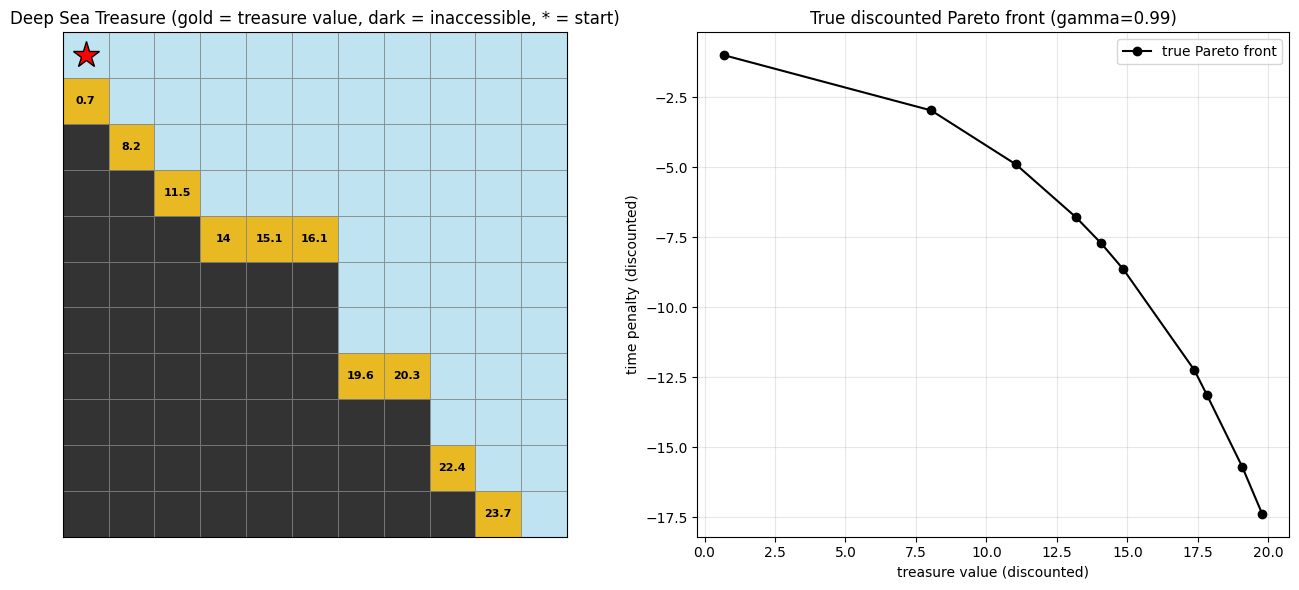

In [9]:
sea_map = env.unwrapped.sea_map
height, width = sea_map.shape


def draw_domain(ax):
    for r in range(height):
        for c in range(width):
            val = sea_map[r, c]
            if val == -10:
                color, label = "#333333", ""
            elif val == 0:
                color, label = "#bfe3f0", ""
            else:
                color, label = "#e8b923", f"{val:g}"
            rect = mpatches.Rectangle((c, height - r - 1), 1, 1, facecolor=color, edgecolor="gray", linewidth=0.5)
            ax.add_patch(rect)
            if label:
                ax.text(c + 0.5, height - r - 1 + 0.5, label, ha="center", va="center", fontsize=8, fontweight="bold")
    ax.set_xlim(0, width)
    ax.set_ylim(0, height)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect("equal")


def cell_center(r, c):
    return c + 0.5, height - r - 1 + 0.5


fig, axes = plt.subplots(1, 2, figsize=(13, 6))

draw_domain(axes[0])
sx, sy = cell_center(0, 0)
axes[0].plot(sx, sy, marker="*", markersize=20, color="red", markeredgecolor="black", zorder=5)
axes[0].set_title("Deep Sea Treasure (gold = treasure value, dark = inaccessible, * = start)")

tf = np.array(true_front)
axes[1].plot(tf[:, 0], tf[:, 1], "o-", color="black", label="true Pareto front")
axes[1].set_xlabel("treasure value (discounted)")
axes[1].set_ylabel("time penalty (discounted)")
axes[1].set_title(f"True discounted Pareto front (gamma={GAMMA})")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 3. Train OKB

Two things happen every outer iteration: a new **base policy** gets trained (OLS picks the
weight, exactly like SFOLS) and added to the CCS if it's non-dominated, then the **Option
Keyboard** gets updated by relabelling existing replay-buffer transitions with new preference
vectors (no new environment steps needed for that part) and running `NUM_OK_ITERATIONS` rounds
of its own weight-selection + training loop.


In [10]:
def agent_constructor():
    return OKB(
        env,
        gamma=GAMMA,
        learning_rate=3e-4,
        ok_learning_rate=1e-3,
        gradient_updates=G,
        ok_gradient_updates=G,
        num_nets=NUM_NETS,
        use_ok=True,
        weight_selection="okb",
        initial_ok_task="one-hot",
        top_k_ok=TOP_K_OK,
        top_k_base=1,
        num_ok_iterations=NUM_OK_ITERATIONS,
        batch_size=64,
        net_arch=[128, 128, 128],
        ok_net_arch=[128, 128],
        buffer_size=int(2e5),
        initial_epsilon=1.0,
        final_epsilon=0.05,
        epsilon_decay_steps=TIMESTEPS_PER_ITERATION,
        learning_starts=200,
        alpha_per=0.6,
        min_priority=0.1,
        per=True,
        batch_norm_momentum=0.99,
        drop_rate=0.01,
        layer_norm=True,
        gpi_type="gpi",
        target_net_update_freq=200,
        tau=1,
        log=False,               # no wandb needed for this notebook
        project_name="OKB-DST",
        experiment_name="notebook",
        seed=SEED,
    )


agent = agent_constructor()

agent.learn(
    eval_env=eval_env,
    timesteps_per_iteration=TIMESTEPS_PER_ITERATION,
    num_iterations=NUM_ITERATIONS,
    test_tasks=incremental_weights(2, n_partitions=10),
    rep_eval=5,
    save_dir=None,
)


Next w base policies: [1. 0.]
Episode: 100 Step: 816, Ep. Total Reward: [ 0.7 -3. ]
Episode: 200 Step: 1483, Ep. Total Reward: [ 0.7 -1. ]
Episode: 300 Step: 2211, Ep. Total Reward: [ 15.1 -15. ]
Episode: 400 Step: 3229, Ep. Total Reward: [11.5 -9. ]
Adding value [ 17.3731 -12.2479] for weight [1. 0.]
CCS: [array([ 17.3731, -12.2479], dtype=float32)] CCS size: 1
Weight Support Set: [array([1., 0.], dtype=float32)]
OK LOOP:
OK buffer size before: 3838
OK buffer size after: 3735
ccs: []
ccs size: 0
Episode: 572 Step: 4118, Ep. Total Reward: [ 0.7 -1. ]
Episode: 672 Step: 4244, Ep. Total Reward: [ 0.7 -1. ]
Episode: 772 Step: 4597, Ep. Total Reward: [ 0.7 -1. ]


KeyboardInterrupt: 

## 4. Discovered CCS vs. the true Pareto front

In [ ]:
base_weights = np.array(agent.ols.get_ccs_weights())
base_values = np.array(agent.ols.ccs)
ok_weights = np.array(agent.ols_ok.get_ccs_weights())
ok_values = np.array(agent.ols_ok.ccs)

print(f"Base CCS size: {len(base_values)}   |   OK CCS size: {len(ok_values)}")

base_df = pd.DataFrame(base_values, columns=["treasure", "time"])
base_df.insert(0, "w_treasure", base_weights[:, 0])
base_df.insert(1, "w_time", base_weights[:, 1])
print("\nBase CCS:")
display(base_df)

ok_df = pd.DataFrame(ok_values, columns=["treasure", "time"])
ok_df.insert(0, "w_treasure", ok_weights[:, 0])
ok_df.insert(1, "w_time", ok_weights[:, 1])
print("\nOK CCS:")
display(ok_df)


In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(tf[:, 0], tf[:, 1], "o-", color="black", label="true Pareto front", zorder=1, alpha=0.6)
ax.scatter(base_values[:, 0], base_values[:, 1], marker="^", s=90, color="tab:blue", label="base CCS (SFOLS-style)", zorder=3)
ax.scatter(ok_values[:, 0], ok_values[:, 1], marker="s", s=70, color="tab:red", label="OK CCS", zorder=2)
ax.set_xlabel("treasure value (discounted)")
ax.set_ylabel("time penalty (discounted)")
ax.set_title("Discovered CCS vs. true optimum")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Does the Option Keyboard actually beat plain GPI?

`agent.eval(obs, w)`'s behavior is entirely controlled by two flags: `use_ok` and `use_gpi`
(see `okb.py:1413`). Toggling them reproduces exactly the 3-way comparison the training loop
itself logs to wandb every iteration:

- **OK** (`use_ok=True`): the trained Option Keyboard policy -- can interpolate between base
  skills within an episode.
- **GPI** (`use_ok=False, use_gpi=True`): picks the single best *base* policy per state via
  generalized policy improvement -- can switch between skills, but not blend them.
- **Single** (`use_ok=False, use_gpi=False`): the best policy in the base CCS evaluated
  directly against `w`, no composition at all.

We sweep a fine set of preferences and compare the scalarized utility each mode achieves
against the true optimum (computed exactly from the known Pareto front).


In [ ]:
sweep_weights = incremental_weights(2, n_partitions=20)
eval_env_lr = LinearReward(make_env())

rows = []
for w in sweep_weights:
    w = np.asarray(w, dtype=np.float32)
    true_utility = max(np.dot(w, v) for v in true_front)

    agent.use_gpi, agent.use_ok = True, True
    v_ok = policy_evaluation_mo(agent, eval_env_lr, w, rep=5)

    agent.use_gpi, agent.use_ok = True, False
    v_gpi = policy_evaluation_mo(agent, eval_env_lr, w, rep=5)

    agent.use_gpi, agent.use_ok = False, False
    v_single = policy_evaluation_mo(agent, eval_env_lr, w, rep=5)

    rows.append(dict(
        w0=w[0],
        true=true_utility,
        ok=np.dot(w, v_ok),
        gpi=np.dot(w, v_gpi),
        single=np.dot(w, v_single),
    ))

agent.use_gpi, agent.use_ok = True, True  # restore default mode

sweep_df = pd.DataFrame(rows).sort_values("w0")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sweep_df.w0, sweep_df.true, "k--", label="true optimum", linewidth=2)
ax.plot(sweep_df.w0, sweep_df.ok, "o-", color="tab:red", label="OK", markersize=4)
ax.plot(sweep_df.w0, sweep_df.gpi, "s-", color="tab:blue", label="GPI (base CCS only)", markersize=4)
ax.plot(sweep_df.w0, sweep_df.single, "^-", color="tab:green", label="single best base policy", markersize=4, alpha=0.7)
ax.set_xlabel("preference weight on treasure  (w = [w0, 1-w0])")
ax.set_ylabel("scalarized utility  w . value")
ax.set_title("Utility vs. preference: OK vs. GPI vs. single policy vs. true optimum")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Mean gap to optimum -- OK: {(sweep_df.true - sweep_df.ok).mean():.3f}   "
      f"GPI: {(sweep_df.true - sweep_df.gpi).mean():.3f}   "
      f"Single: {(sweep_df.true - sweep_df.single).mean():.3f}")


## 6. Rollout trajectories for a few preferences

In [ ]:
def rollout(agent, w, max_steps=50):
    agent.use_gpi, agent.use_ok = True, True
    obs, _ = eval_env.reset()
    traj = [tuple(obs)]
    acc_vec_reward = np.zeros(2)
    for _ in range(max_steps):
        action = agent.eval(obs, w)
        obs, r, terminated, truncated, info = eval_env.step(action)
        traj.append(tuple(obs))
        acc_vec_reward += r
        if terminated or truncated:
            break
    return traj, acc_vec_reward


test_weights = {
    "treasure-focused (w=[1,0])": np.array([1.0, 0.0], dtype=np.float32),
    "balanced (w=[0.5,0.5])": np.array([0.5, 0.5], dtype=np.float32),
    "time-focused (w=[0,1])": np.array([0.0, 1.0], dtype=np.float32),
}

fig, ax = plt.subplots(figsize=(7, 7))
draw_domain(ax)
colors = {"treasure-focused (w=[1,0])": "tab:red", "balanced (w=[0.5,0.5])": "tab:purple", "time-focused (w=[0,1])": "tab:blue"}

for label, w in test_weights.items():
    traj, acc = rollout(agent, w)
    color = colors[label]
    for i in range(len(traj) - 1):
        x0, y0 = cell_center(*traj[i])
        x1, y1 = cell_center(*traj[i + 1])
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                    arrowprops=dict(arrowstyle="->", color=color, lw=2, alpha=0.85, shrinkA=0, shrinkB=0))
    print(f"{label}: {len(traj)-1} steps, final position {traj[-1]}, "
          f"accumulated reward [treasure={acc[0]:.1f}, time={acc[1]:.1f}]")

sx, sy = cell_center(0, 0)
ax.plot(sx, sy, marker="*", markersize=20, color="black", zorder=5)
legend_handles = [mpatches.Patch(color=c, label=l) for l, c in colors.items()]
ax.legend(handles=legend_handles, bbox_to_anchor=(1.02, 1), loc="upper left")
ax.set_title("OK rollout trajectories for different preferences")
plt.tight_layout()
plt.show()


## 7. Inside the Option Keyboard: how does its internal preference evolve?

The OK doesn't just pick an action -- internally it also picks a preference vector `w_ok`
at every step (`OKB.ok_action`, `okb.py:1434`) and acts greedily w.r.t. that. `agent.eval()`
records this in `agent.meta_actions`. For a fixed external task `w`, does the OK actually
keep `w_ok` constant, or does it *change its mind* about which skill-blend to use as the
episode progresses (e.g. once it's committed to a treasure)?


In [ ]:
w = np.array([0.5, 0.5], dtype=np.float32)
agent.use_gpi, agent.use_ok = True, True
agent.meta_actions = []
obs, _ = eval_env.reset()
positions = [tuple(obs)]
for _ in range(50):
    action = agent.eval(obs, w)
    obs, r, terminated, truncated, info = eval_env.step(action)
    positions.append(tuple(obs))
    if terminated or truncated:
        break

meta = np.array(agent.meta_actions)
print(f"External task w = {w}")
print(f"Steps: {len(meta)}")
for t, (pos, w_ok) in enumerate(zip(positions[1:], meta)):
    print(f"  step {t:2d}  pos={pos}  internal w_ok=[{w_ok[0]:+.3f}, {w_ok[1]:+.3f}]")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(meta[:, 0], "o-", label="w_ok[treasure]")
ax.plot(meta[:, 1], "o-", label="w_ok[time]")
ax.axhline(w[0], color="gray", linestyle="--", alpha=0.6, label="external w[treasure]")
ax.set_xlabel("step in episode")
ax.set_ylabel("internal preference component")
ax.set_title(f"Option Keyboard's internal w_ok over the episode (external w={list(w)})")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Summary

- **Base CCS**: SFOLS-style discovery over successor-feature policies -- see section 4 for
  how closely it matches DST's known-optimal discounted Pareto front.
- **OK CCS**: a second CCS discovered by relabelling the *same* environment interactions with
  new preferences (no extra env steps) -- compare its size/coverage to the base CCS above.
- **Section 5 is the actual paper claim, made measurable**: whether OK's utility curve tracks
  the true optimum more closely than plain GPI, especially at preferences that fall *between*
  the base CCS's corner weights, where GPI can only pick one fixed base policy while OK can
  blend.
- **Section 7** is OKB-specific: unlike a fixed-weight policy, the Option Keyboard can commit
  to a different internal preference mid-episode -- worth checking whether that actually
  happens here or whether it locks in early.

To try a different preference distribution or a longer/shorter training budget, edit the
config cell and rerun from section 3 onward.
